In [1]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler

df = pd.read_csv("segmentation data.csv")

X = df.select_dtypes(include=np.number)
X = X.fillna(X.median())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!


In [2]:
# Load Clustering Results

kmeans_df = pd.read_csv("KMeans_Clustering_Results.csv")

hierarchical_df = pd.read_csv("Hierarchical_Clustering_Results.csv")

dbscan_df = pd.read_csv("DBSCAN_Clustering_Results.csv")

print("All Three Clustering Results Loaded Successfully!")

All Three Clustering Results Loaded Successfully!


In [3]:
# Check Cluster Columns

print("K-Means Columns:")
print(kmeans_df.columns.tolist())

print("\nHierarchical Columns:")
print(hierarchical_df.columns.tolist())

print("\nDBSCAN Columns:")
print(dbscan_df.columns.tolist())

K-Means Columns:
['Sex', 'Marital status', 'Age', 'Education', 'Income', 'Occupation', 'Settlement size', 'Cluster']

Hierarchical Columns:
['ID', 'Sex', 'Marital status', 'Age', 'Education', 'Income', 'Occupation', 'Settlement size', 'Hierarchical_Cluster']

DBSCAN Columns:
['ID', 'Sex', 'Marital status', 'Age', 'Education', 'Income', 'Occupation', 'Settlement size', 'DBSCAN_Cluster']


In [4]:
# Extract Cluster Labels

kmeans_labels = kmeans_df['Cluster'].values

hierarchical_labels = hierarchical_df['Hierarchical_Cluster'].values

dbscan_labels = dbscan_df['DBSCAN_Cluster'].values

print("All Cluster Labels Extracted Successfully!")

All Cluster Labels Extracted Successfully!


In [5]:
# Clustering Model Comparison

from sklearn.metrics import silhouette_score, davies_bouldin_score

comparison_results = []

# K-Means
kmeans_silhouette = silhouette_score(X_scaled, kmeans_labels)

kmeans_db = davies_bouldin_score(X_scaled, kmeans_labels)

comparison_results.append({
    'Algorithm': 'K-Means',
    'Number of Clusters': len(set(kmeans_labels)),
    'Silhouette Score': kmeans_silhouette,
    'Davies-Bouldin Score': kmeans_db
})


# Hierarchical Clustering
hierarchical_silhouette = silhouette_score(X_scaled, hierarchical_labels)

hierarchical_db = davies_bouldin_score(X_scaled, hierarchical_labels)

comparison_results.append({
    'Algorithm': 'Hierarchical',
    'Number of Clusters': len(set(hierarchical_labels)),
    'Silhouette Score': hierarchical_silhouette,
    'Davies-Bouldin Score': hierarchical_db
})


# DBSCAN (excluding noise points)
mask = dbscan_labels != -1

dbscan_valid_labels = dbscan_labels[mask]

if len(set(dbscan_valid_labels)) > 1:

    dbscan_silhouette = silhouette_score(
        X_scaled[mask],
        dbscan_valid_labels
    )

    dbscan_db = davies_bouldin_score(
        X_scaled[mask],
        dbscan_valid_labels
    )

else:
    dbscan_silhouette = None
    dbscan_db = None

comparison_results.append({
    'Algorithm': 'DBSCAN',
    'Number of Clusters': len(set(dbscan_labels) - {-1}),
    'Silhouette Score': dbscan_silhouette,
    'Davies-Bouldin Score': dbscan_db
})


# Create Comparison Table

comparison = pd.DataFrame(comparison_results)

print("FINAL CLUSTERING MODEL COMPARISON")
print(comparison)

FINAL CLUSTERING MODEL COMPARISON
      Algorithm  Number of Clusters  Silhouette Score  Davies-Bouldin Score
0       K-Means                   3          0.242313              1.513949
1  Hierarchical                   3          0.163502              1.876638
2        DBSCAN                   5          0.086054              1.150899


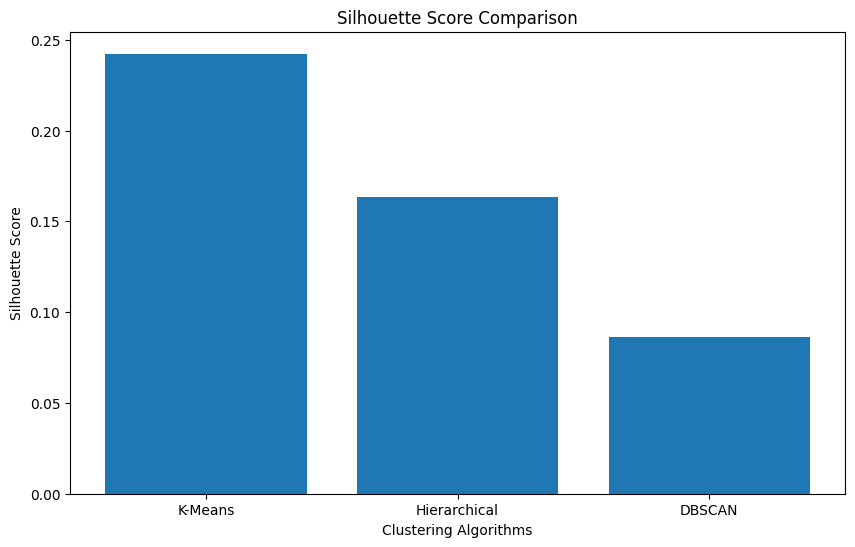

In [6]:
# Silhouette Score Comparison

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    comparison['Algorithm'],
    comparison['Silhouette Score']
)

plt.title("Silhouette Score Comparison")
plt.xlabel("Clustering Algorithms")
plt.ylabel("Silhouette Score")

plt.show()

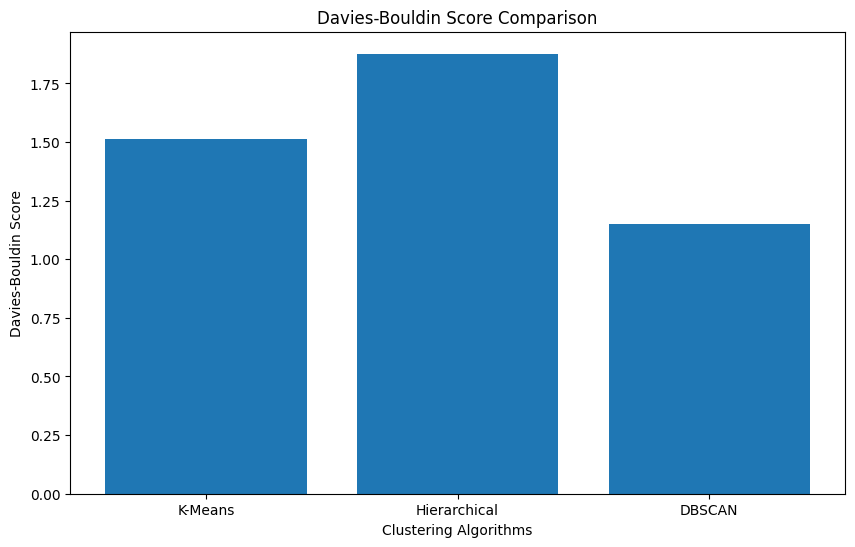

In [7]:
# Davies-Bouldin Score Comparison

plt.figure(figsize=(10, 6))

plt.bar(
    comparison['Algorithm'],
    comparison['Davies-Bouldin Score']
)

plt.title("Davies-Bouldin Score Comparison")
plt.xlabel("Clustering Algorithms")
plt.ylabel("Davies-Bouldin Score")

plt.show()

In [8]:
# Save Final Comparison Results

comparison.to_csv(
    "Clustering_Model_Comparison.csv",
    index=False
)

print("Clustering Model Comparison Saved Successfully!")

Clustering Model Comparison Saved Successfully!
